# Laboratorio: CBIR tradicional sin CNN

**Objetivo:** recuperar imágenes mediante histogramas de color y HOG, calcular distancias y evaluar Precision@5.

Coloque la carpeta `imagenes/` junto a este notebook. El conjunto contiene **48 imágenes sintéticas** (6 clases × 8 imágenes).

In [1]:
# Instalar dependencias solo si es necesario:
# %pip install numpy pillow matplotlib scikit-image
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import hog

DATA = Path('imagenes')
files = sorted(DATA.glob('*.png'))
assert len(files) == 48, f'Se esperaban 48 imágenes, se encontraron {len(files)}. Verifique la carpeta imagenes/'
labels = [p.stem.rsplit('_',1)[0] for p in files]
print('Imágenes:', len(files), '| Clases:', sorted(set(labels)))

Imágenes: 48 | Clases: ['circulos_azules', 'circulos_rojos', 'cuadros_verdes', 'rayas_horizontales', 'rayas_verticales', 'triangulos_amarillos']


## 1. Explorar la colección

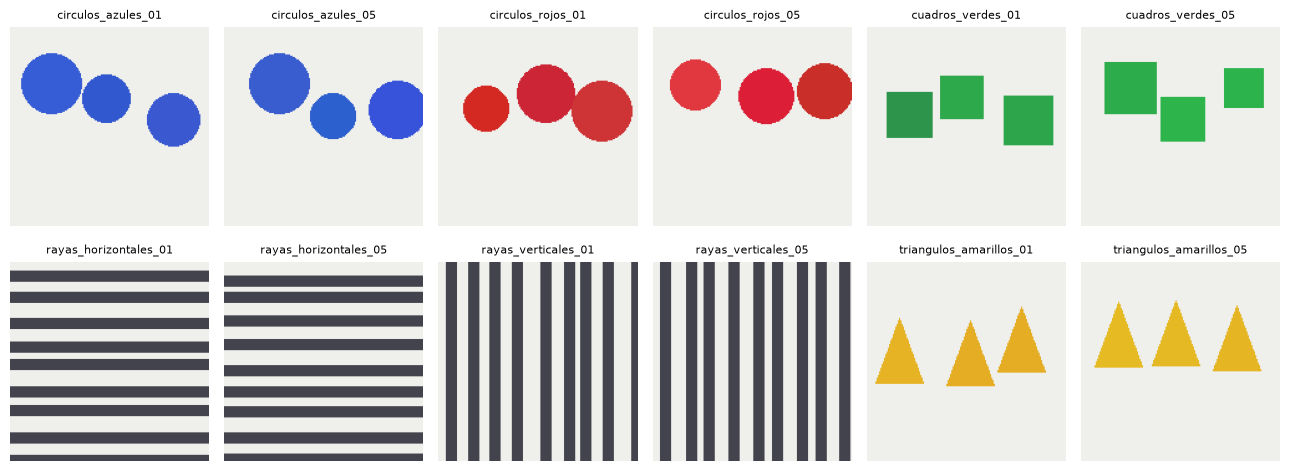

In [2]:
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, p in zip(axes.flat, files[::4][:12]):
    ax.imshow(Image.open(p)); ax.set_title(p.stem, fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Descriptores de color
Un histograma resume cuántos píxeles pertenecen a cada intervalo de intensidad. Se normaliza para que la suma de sus componentes sea 1.

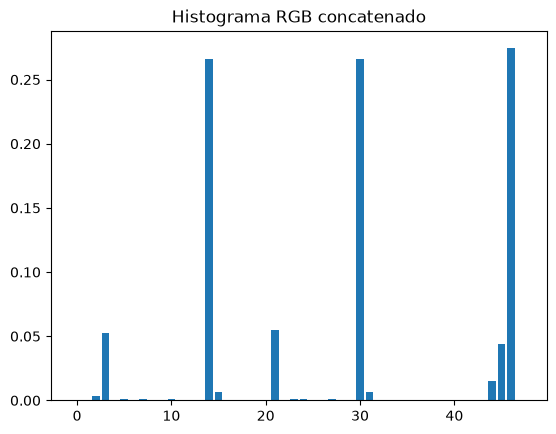

In [3]:
def hist_rgb(path, bins=16):
    arr = np.asarray(Image.open(path).convert('RGB').resize((128,128)))
    parts = [np.histogram(arr[:,:,c], bins=bins, range=(0,256))[0] for c in range(3)]
    v = np.concatenate(parts).astype(float)
    return v / (v.sum() + 1e-12)

def hist_hsv(path, bins=16):
    arr = np.asarray(Image.open(path).convert('HSV').resize((128,128)))
    parts = [np.histogram(arr[:,:,c], bins=bins, range=(0,256))[0] for c in range(3)]
    v = np.concatenate(parts).astype(float)
    return v / (v.sum() + 1e-12)

query = files[0]
plt.bar(np.arange(48), hist_rgb(query)); plt.title('Histograma RGB concatenado'); plt.show()

## 3. Descriptor de textura: HOG
HOG cuenta orientaciones de gradientes locales. Es útil para distinguir patrones con diferentes direcciones.

In [4]:
def desc_hog(path):
    gray = np.asarray(Image.open(path).convert('L').resize((128,128)), dtype=float) / 255
    v = hog(gray, orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2), feature_vector=True)
    return v / (np.linalg.norm(v) + 1e-12)

print('Dimensión RGB:',len(hist_rgb(query)), 'HOG:',len(desc_hog(query)))

Dimensión RGB: 48 HOG: 1764


## 4. Distancias y ranking
La distancia euclidiana es menor para vectores cercanos; la distancia coseno es `1 − similitud coseno`.

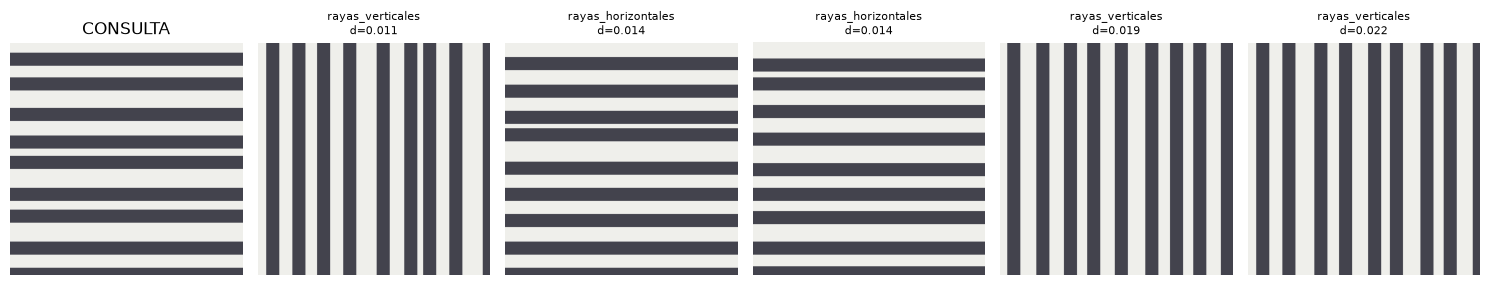

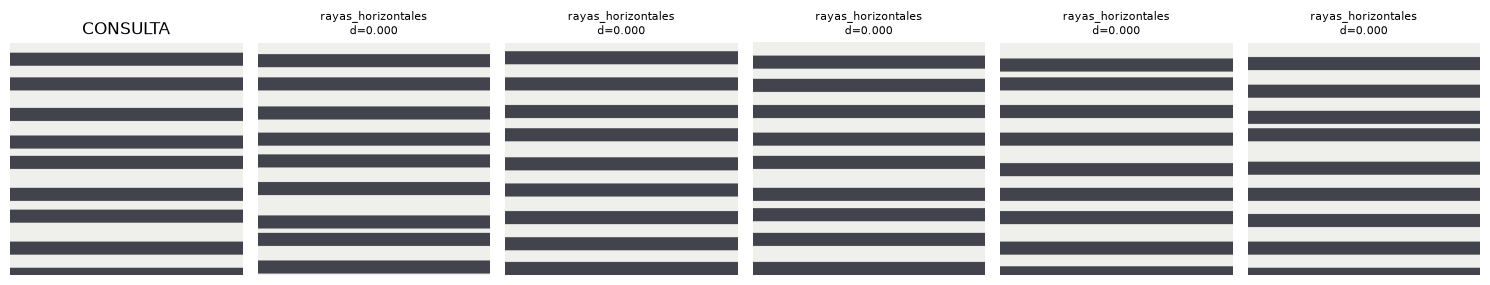

In [5]:
def distancia(a, b, metrica='euclidiana'):
    if metrica == 'euclidiana': return float(np.linalg.norm(a-b))
    if metrica == 'manhattan': return float(np.abs(a-b).sum())
    if metrica == 'coseno': return float(1 - np.dot(a,b)/((np.linalg.norm(a)*np.linalg.norm(b))+1e-12))
    raise ValueError('Métrica no reconocida')

def buscar(indice_consulta, descriptor='rgb', metrica='euclidiana', k=5):
    extractor = {'rgb':hist_rgb, 'hsv':hist_hsv, 'hog':desc_hog}[descriptor]
    vectores = [extractor(p) for p in files]
    ranking = sorted(((i, distancia(vectores[indice_consulta],v,metrica)) for i,v in enumerate(vectores) if i != indice_consulta), key=lambda x:x[1])
    return ranking[:k]

def mostrar(indice_consulta, resultados):
    fig,axs=plt.subplots(1,len(resultados)+1,figsize=(15,3))
    axs[0].imshow(Image.open(files[indice_consulta]));axs[0].set_title('CONSULTA')
    for ax,(i,d) in zip(axs[1:],resultados):
        ax.imshow(Image.open(files[i]));ax.set_title(f'{labels[i]}\nd={d:.3f}',fontsize=8)
    for ax in axs:ax.axis('off')
    plt.tight_layout();plt.show()

indice_consulta = next(i for i,p in enumerate(files) if p.stem=='rayas_horizontales_01')
mostrar(indice_consulta,buscar(indice_consulta,'rgb'))
mostrar(indice_consulta,buscar(indice_consulta,'hog','coseno'))

## 5. Evaluación
En este conjunto didáctico, una imagen es relevante si pertenece a la misma categoría que la consulta. Se excluye la consulta, por lo que existen 7 relevantes posibles.

In [6]:
def precision_at_k(i, resultados):
    return sum(labels[j] == labels[i] for j,_ in resultados)/len(resultados)

for desc in ['rgb','hsv','hog']:
    metric = 'coseno' if desc=='hog' else 'euclidiana'
    scores=[precision_at_k(i,buscar(i,desc,metric,k=5)) for i in range(len(files))]
    print(f'{desc:4} | Precision@5 promedio: {np.mean(scores):.3f}')

rgb  | Precision@5 promedio: 0.808


hsv  | Precision@5 promedio: 0.779


hog  | Precision@5 promedio: 0.821


## 6. Actividades para entregar
1. Seleccione una consulta de círculos rojos y compare los resultados RGB, HSV y HOG.
2. Explique por qué un descriptor basado solo en color puede confundir rayas horizontales y verticales.
3. Cambie `bins` de 16 a 8 y 32: ¿qué cambia en la representación y los resultados?
4. Compare distancia euclidiana y coseno para una misma consulta.
5. Proponga un descriptor combinado (color + textura) y justifique los pesos.

**Preguntas de reflexión:** ¿qué entiende el algoritmo por similitud? ¿En qué casos falla? ¿Cómo influye la colección?

## Actividad 1: círculos rojos con RGB, HSV y HOG

RGB: P@5 = 1.00


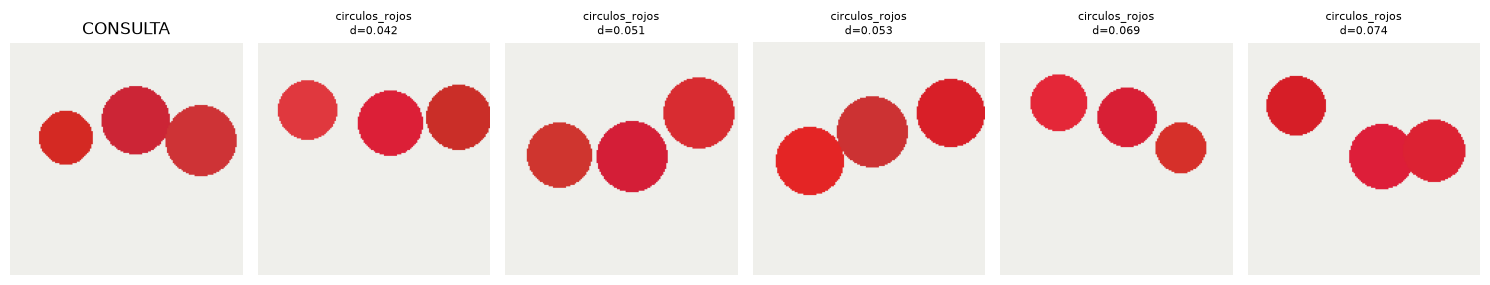

HSV: P@5 = 1.00


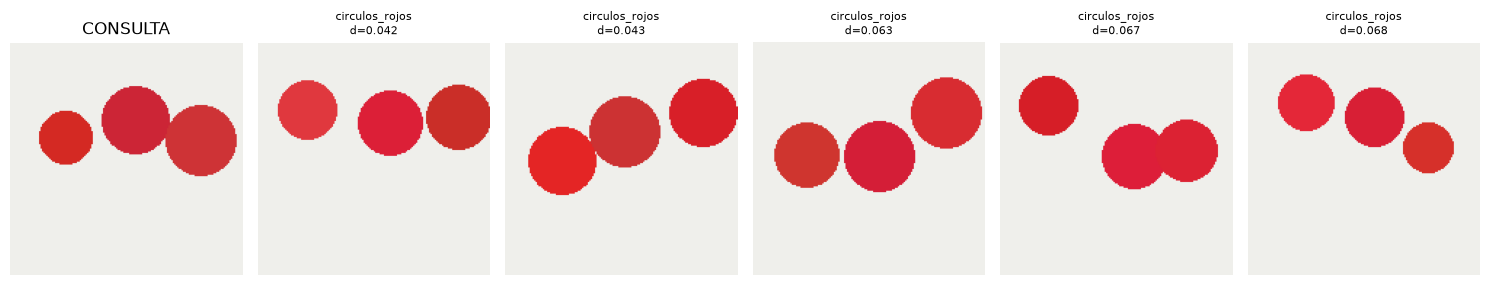

HOG: P@5 = 0.40


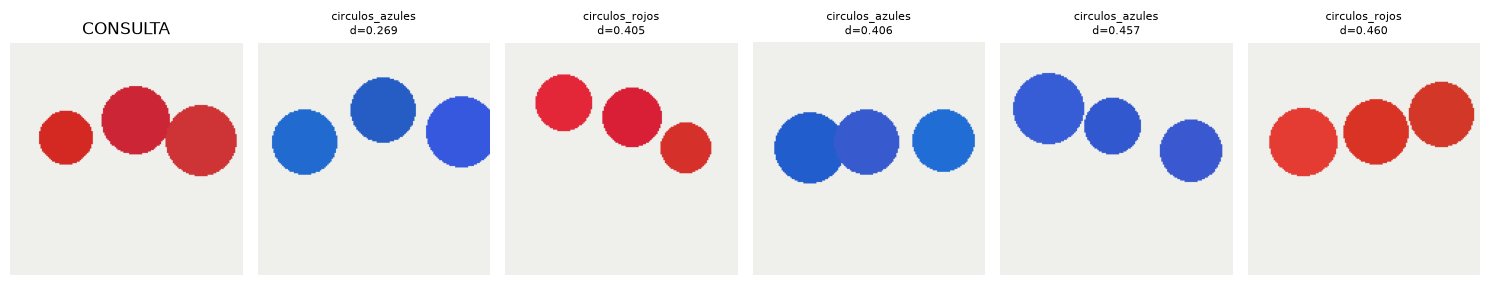

In [7]:
q1 = next(i for i,p in enumerate(files) if p.stem == 'circulos_rojos_01')
for desc, met in [('rgb','euclidiana'), ('hsv','euclidiana'), ('hog','coseno')]:
    res = buscar(q1, desc, met)
    print(f'{desc.upper()}: P@5 = {precision_at_k(q1, res):.2f}')
    mostrar(q1, res)

## Actividad 2: rayas horizontales vs verticales con un descriptor de color

RGB: P@5 = 0.40


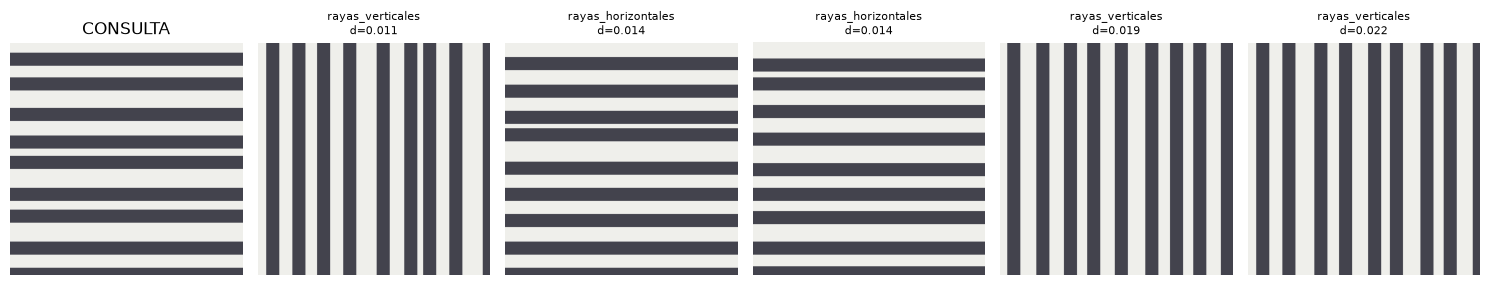

HOG: P@5 = 1.00


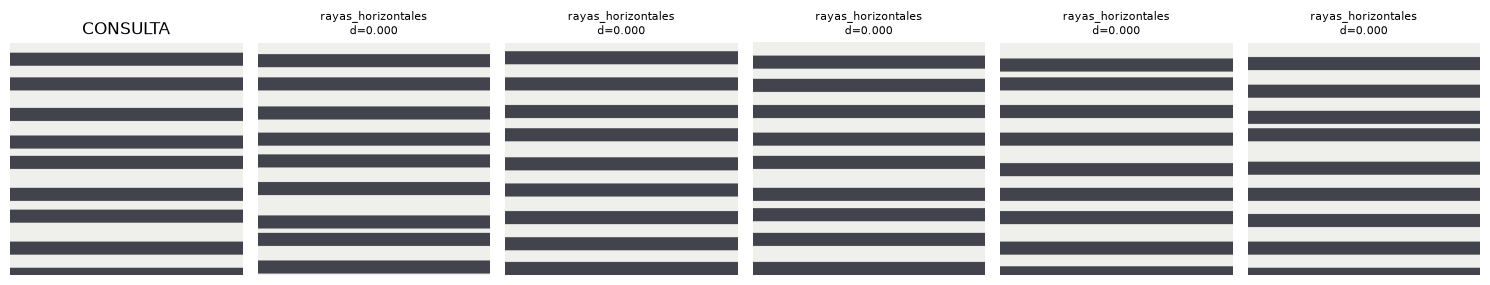

Distancia horizontal_01 vs vertical_01:
  RGB (euclidiana): 0.011
  HOG (coseno):     1.0


In [8]:
q2 = next(i for i,p in enumerate(files) if p.stem == 'rayas_horizontales_01')
v2 = next(i for i,p in enumerate(files) if p.stem == 'rayas_verticales_01')

for desc, met in [('rgb','euclidiana'), ('hog','coseno')]:
    res = buscar(q2, desc, met)
    print(f'{desc.upper()}: P@5 = {precision_at_k(q2, res):.2f}')
    mostrar(q2, res)

print('Distancia horizontal_01 vs vertical_01:')
print('  RGB (euclidiana):', round(distancia(hist_rgb(files[q2]), hist_rgb(files[v2])), 3))
print('  HOG (coseno):    ', round(distancia(desc_hog(files[q2]), desc_hog(files[v2]), 'coseno'), 3))

## Actividad 3: bins = 8, 16 y 32

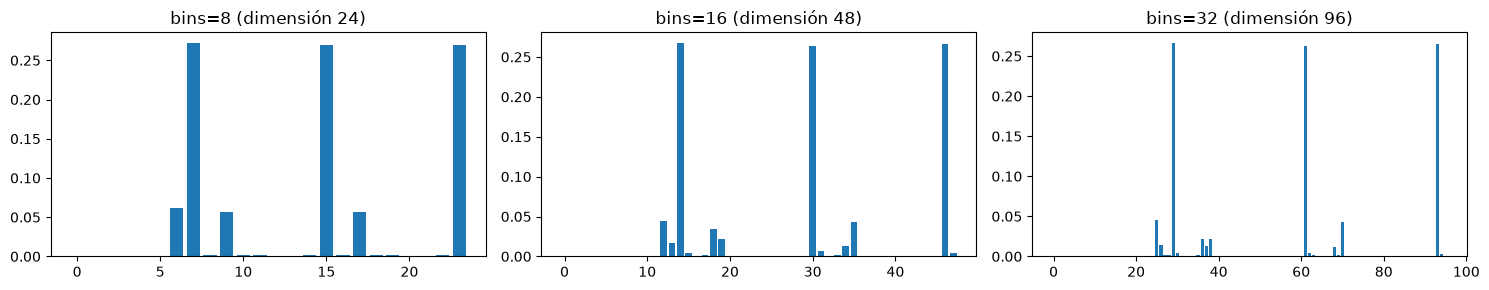

bins= 8 | P@5 RGB: 0.804 | P@5 HSV: 0.771
bins=16 | P@5 RGB: 0.808 | P@5 HSV: 0.779


bins=32 | P@5 RGB: 0.800 | P@5 HSV: 0.763


In [9]:
def p5_promedio(extractor, bins):
    V = np.array([extractor(p, bins) for p in files])
    scores = []
    for i in range(len(files)):
        d = np.linalg.norm(V - V[i], axis=1); d[i] = np.inf   # excluye la consulta
        scores.append(np.mean([labels[j] == labels[i] for j in np.argsort(d)[:5]]))
    return np.mean(scores)

# Representación: el mismo histograma RGB con distinto número de bins
fig, axs = plt.subplots(1, 3, figsize=(15, 3))
for ax, b in zip(axs, [8, 16, 32]):
    ax.bar(np.arange(3*b), hist_rgb(files[q1], b)); ax.set_title(f'bins={b} (dimensión {3*b})')
plt.tight_layout(); plt.show()

# Resultados
for b in [8, 16, 32]:
    print(f'bins={b:2} | P@5 RGB: {p5_promedio(hist_rgb, b):.3f} | P@5 HSV: {p5_promedio(hist_hsv, b):.3f}')

## Explicación de los resultados

**1. Círculos rojos:** RGB y HSV obtienen P@5 = 1.00 y HOG obtiene 0.40. El rojo solo aparece en esa clase, así que el color basta para identificarla. HOG trabaja en escala de grises y solo describe la forma de los bordes. Por eso un círculo rojo y uno azul le parecen iguales y devuelve círculos azules.

**2. Rayas:** con RGB, el resultado más cercano a `rayas_horizontales_01` es una raya **vertical** (d = 0.011). Las dos imágenes tienen los mismos colores en la misma proporción. El histograma solo cuenta *cuántos* píxeles hay de cada color, no *dónde* están, así que girar la imagen 90° no cambia el histograma. HOG mide la orientación de los bordes: obtiene P@5 = 1.00 y distancia coseno 1.0 entre horizontal y vertical, es decir, vectores sin nada en común.

**3. Bins:** los bins definen qué tan fino se divide cada canal. 8 bins dan un vector de 24 valores (colores agrupados en rangos amplios) y 32 bins dan 96 (rangos estrechos). P@5 casi no cambia (≈0.80 en RGB, ≈0.77 en HSV) porque las imágenes tienen pocos colores muy distintos y se separan bien con cualquier resolución. Lo que no mejora en ningún caso son las rayas: más bins no agregan información espacial.

**Conclusión:** cada descriptor mide un solo tipo de similitud. El color sirve cuando la clase se distingue por su color y HOG cuando se distingue por la forma o la orientación.